In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

# --- 1. Preprocessing ---
df = pd.read_csv("college_iot_energy_monitoring.csv")
X = df.drop(columns=["energy", "cluster"], errors="ignore").copy()

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
])
X_scaled = preprocessor.fit_transform(X)
print("Dataset shape:", X.shape)
print("Processed feature shape:", X_scaled.shape)

Dataset shape: (1961, 7)
Processed feature shape: (1961, 16)


In [9]:
# --- 2. K-Means++ Clustering and Tuning ---
kmeans_results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)
    kmeans_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)
    })
kmeans_df = pd.DataFrame(kmeans_results)
print("\n--- K-Means Results ---")
print(kmeans_df.round(4))

best_k = int(kmeans_df.loc[kmeans_df["silhouette"].idxmax(), "k"])
best_kmeans = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=42)
df["kmeans_cluster"] = best_kmeans.fit_predict(X_scaled)


--- K-Means Results ---
    k     inertia  silhouette
0   2  11504.9192      0.1451
1   3  10123.3017      0.1561
2   4   9290.3202      0.1465
3   5   8688.5196      0.1340
4   6   8166.3640      0.1359
5   7   7740.4173      0.1342
6   8   7385.3961      0.1385
7   9   7094.9415      0.1387
8  10   6877.8530      0.1350


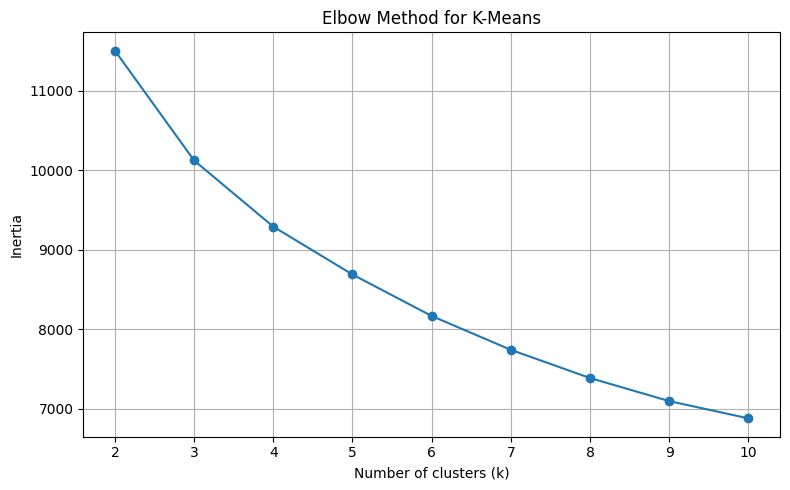

In [10]:
# --- 3. Elbow Method Plotting ---
plt.figure(figsize=(8, 5))
plt.plot(kmeans_df["k"], kmeans_df["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
# --- 4. Agglomerative Clustering and Tuning ---
agg_results = []
for linkage in ["ward", "complete", "average", "single"]:
    metrics = ["euclidean"] if linkage == "ward" else ["euclidean", "manhattan"]
    for metric in metrics:
        for k in range(2, 11):
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage, metric=metric)
            labels = model.fit_predict(X_scaled)
            score = silhouette_score(X_scaled, labels)
            agg_results.append({
                "n_clusters": k,
                "linkage": linkage,
                "metric": metric,
                "silhouette": score
            })
agg_df = pd.DataFrame(agg_results).sort_values("silhouette", ascending=False)
print("\n--- Top 5 Agglomerative Combinations ---")
print(agg_df.head(5).round(4))

best_agg_config = agg_df.iloc[0]
best_agg = AgglomerativeClustering(
    n_clusters=int(best_agg_config["n_clusters"]),
    linkage=best_agg_config["linkage"],
    metric=best_agg_config["metric"]
)
df["agglomerative_cluster"] = best_agg.fit_predict(X_scaled)


--- Top 5 Agglomerative Combinations ---
    n_clusters   linkage     metric  silhouette
27           2   average  euclidean      0.2261
9            2  complete  euclidean      0.2134
36           2   average  manhattan      0.1807
54           2    single  manhattan      0.1807
18           2  complete  manhattan      0.1776


Number of clusters: 3
Noise points: 87

Cluster counts:
cluster
-1      87
 0     159
 1    1520
 2     195
Name: count, dtype: int64
Silhouette score: 0.1083


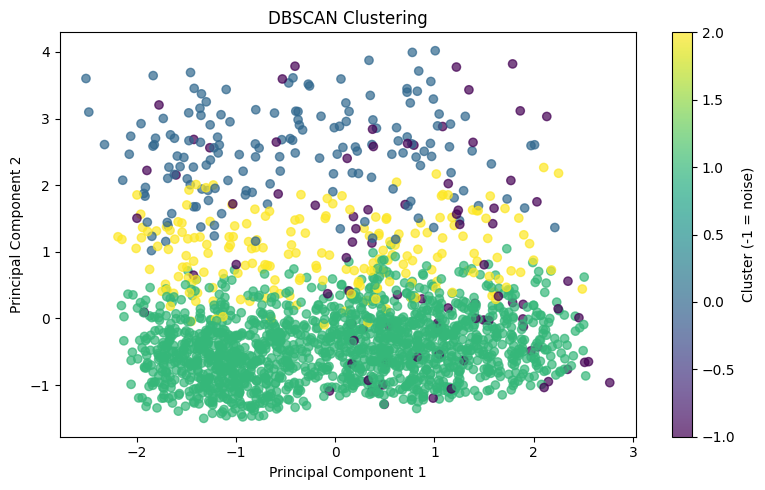

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv("college_iot_energy_monitoring.csv")

# Exclude target energy from clustering
X = df.drop(columns=["energy"])

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Scale numerical features and encode device
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_cols)
])

X_scaled = preprocessor.fit_transform(X)

if hasattr(X_scaled, "toarray"):
    X_scaled = X_scaled.toarray()

# Train DBSCAN
dbscan = DBSCAN(
    eps=1.5,
    min_samples=6
)

labels = dbscan.fit_predict(X_scaled)
df["cluster"] = labels

# Results
cluster_labels = set(labels) - {-1}

print("Number of clusters:", len(cluster_labels))
print("Noise points:", np.sum(labels == -1))
print("\nCluster counts:")
print(df["cluster"].value_counts().sort_index())

# Silhouette score, excluding noise
mask = labels != -1

if len(set(labels[mask])) > 1:
    print(
        "Silhouette score:",
        round(silhouette_score(X_scaled[mask], labels[mask]), 4)
    )

# Visualize using PCA
X_2d = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=labels,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clustering")
plt.colorbar(label="Cluster (-1 = noise)")
plt.tight_layout()
plt.show()

# Save output
df.to_csv("iot_energy_dbscan_3_clusters.csv", index=False)